## A deployed multi-criteria decision model for evaluating competing offers in United States residential real estate

Five competing offers on a single residential listing are ranked across six criteria using the
Analytic Hierarchy Process. The same priorities are then applied to TOPSIS as an independent
check on the ranking, and the result is tested for robustness in three ways: removing criteria
(ablation), perturbing the pairwise judgements, and changing the transformation used to invert
the cost criteria.

Criteria: Net Proceeds (NP), Certainty of Close (CoC), Timeline Fit (TF), Contingency Risk (CR),
Seller Expense Impact (SEI), Immediate Possession Fit (IPF).

#### Setup

In [1]:
import os
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kendalltau

warnings.filterwarnings('ignore')

In [2]:
# shared chart settings so every saved chart comes out at the same size and weight
# figures live in the repository root; fall back to a local folder if run elsewhere
FIGDIR = "../figures/" if os.path.isdir("../figures") else "figures/"
os.makedirs(FIGDIR, exist_ok=True)

FIGSTYLE = {
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 9,
    "axes.grid": False,
    "figure.dpi": 300,
}
PALETTE = ["#4c72b0", "#dd8452", "#55a868", "#c44e52", "#8172b3"]

#### Offer data (from platform form submissions)

Five offers received on one listing. Personally identifying information was removed before
release; offer ids are sequential within this set and are not platform keys.

In [3]:
offers_json = [
    {
        "id": 1,
        "offer_price": 380000,
        "earnest_money": 10000,
        "proposed_closing_date": "2025-10-20",
        "immediate_possession": "yes",
        "discount_amount": 15000,
        "buyer_agent_commission": {"paid_by_seller": "no", "amount": 0},
        "buyer_closing_cost": {"paid_by_seller": "no", "amount": 0},
        "down_payment_assistance": {"paid_by_seller": "yes", "amount": 5000},
        "additional_assistance": {"required_by_buyer": "no", "amount": 0},
        "repairs": {"paid_by_seller": "yes", "amount": 2000},
        "replacement_items": {"paid_by_seller": "no", "amount": 0},
        "other_requests": {"requested_by_buyer": "no", "amount": 0},
        "inspection_request": {"requested": "yes", "days": 7},
        "cash_offer": {"all_cash": "no", "bank_loan_amount": 350000},
        "down_payment_to_bank": 30000,
        "other_financing": "None",
        "sale_contingent_on_other_property": "no",
        "property_tax_payment": "buyer/seller pro rate"
    },
    {
        "id": 2,
        "offer_price": 385000,
        "earnest_money": 12000,
        "proposed_closing_date": "2025-10-25",
        "immediate_possession": "no",
        "discount_amount": 10000,
        "buyer_agent_commission": {"paid_by_seller": "yes", "amount": 4000},
        "buyer_closing_cost": {"paid_by_seller": "no", "amount": 0},
        "down_payment_assistance": {"paid_by_seller": "no", "amount": 0},
        "additional_assistance": {"required_by_buyer": "no", "amount": 0},
        "repairs": {"paid_by_seller": "yes", "amount": 1500},
        "replacement_items": {"paid_by_seller": "no", "amount": 0},
        "other_requests": {"requested_by_buyer": "no", "amount": 0},
        "inspection_request": {"requested": "yes", "days": 10},
        "cash_offer": {"all_cash": "yes", "bank_loan_amount": 0},
        "down_payment_to_bank": 0,
        "other_financing": "None",
        "sale_contingent_on_other_property": "no",
        "property_tax_payment": "seller pay all"
    },
    {
        "id": 3,
        "offer_price": 390000,
        "earnest_money": 15000,
        "proposed_closing_date": "2025-10-30",
        "immediate_possession": "yes",
        "discount_amount": 5000,
        "buyer_agent_commission": {"paid_by_seller": "no", "amount": 0},
        "buyer_closing_cost": {"paid_by_seller": "yes", "amount": 2000},
        "down_payment_assistance": {"paid_by_seller": "yes", "amount": 7000},
        "additional_assistance": {"required_by_buyer": "no", "amount": 0},
        "repairs": {"paid_by_seller": "no", "amount": 0},
        "replacement_items": {"paid_by_seller": "yes", "amount": 1000},
        "other_requests": {"requested_by_buyer": "yes", "amount": 500},
        "inspection_request": {"requested": "yes", "days": 5},
        "cash_offer": {"all_cash": "no", "bank_loan_amount": 350000},
        "down_payment_to_bank": 35000,
        "other_financing": "Contract for deed",
        "sale_contingent_on_other_property": "yes",
        "property_tax_payment": "buyer pay all"
    },
    {
        "id": 4,
        "offer_price": 382000,
        "earnest_money": 10000,
        "proposed_closing_date": "2025-10-28",
        "immediate_possession": "no",
        "discount_amount": 8000,
        "buyer_agent_commission": {"paid_by_seller": "no", "amount": 0},
        "buyer_closing_cost": {"paid_by_seller": "no", "amount": 0},
        "down_payment_assistance": {"paid_by_seller": "no", "amount": 0},
        "additional_assistance": {"required_by_buyer": "no", "amount": 0},
        "repairs": {"paid_by_seller": "yes", "amount": 2500},
        "replacement_items": {"paid_by_seller": "no", "amount": 0},
        "other_requests": {"requested_by_buyer": "no", "amount": 0},
        "inspection_request": {"requested": "yes", "days": 8},
        "cash_offer": {"all_cash": "yes", "bank_loan_amount": 0},
        "down_payment_to_bank": 0,
        "other_financing": "None",
        "sale_contingent_on_other_property": "no",
        "property_tax_payment": "seller pay all"
    },
    {
        "id": 5,
        "offer_price": 387000,
        "earnest_money": 12000,
        "proposed_closing_date": "2025-10-26",
        "immediate_possession": "yes",
        "discount_amount": 3000,
        "buyer_agent_commission": {"paid_by_seller": "yes", "amount": 3000},
        "buyer_closing_cost": {"paid_by_seller": "no", "amount": 0},
        "down_payment_assistance": {"paid_by_seller": "no", "amount": 0},
        "additional_assistance": {"required_by_buyer": "no", "amount": 0},
        "repairs": {"paid_by_seller": "yes", "amount": 1000},
        "replacement_items": {"paid_by_seller": "no", "amount": 0},
        "other_requests": {"requested_by_buyer": "no", "amount": 0},
        "inspection_request": {"requested": "yes", "days": 6},
        "cash_offer": {"all_cash": "no", "bank_loan_amount": 350000},
        "down_payment_to_bank": 37000,
        "other_financing": "None",
        "sale_contingent_on_other_property": "no",
        "property_tax_payment": "buyer/seller pro rate"
    }
]

In [4]:
offers = offers_json
offer_index = [f"Offer {o['id']}" for o in offers]
offer_labels = [f"O{o['id']}" for o in offers]

offers_df = pd.DataFrame(offers)
offers_df

,id,offer_price,earnest_money,proposed_closing_date,immediate_possession,discount_amount,buyer_agent_commission,buyer_closing_cost,down_payment_assistance,additional_assistance,repairs,replacement_items,other_requests,inspection_request,cash_offer,down_payment_to_bank,other_financing,sale_contingent_on_other_property,property_tax_payment
0,1,380000,10000,2025-10-20,yes,15000,"{'paid_by_seller': 'no', 'amount': 0}","{'paid_by_seller': 'no', 'amount': 0}","{'paid_by_seller': 'yes', 'amount': 5000}","{'required_by_buyer': 'no', 'amount': 0}","{'paid_by_seller': 'yes', 'amount': 2000}","{'paid_by_seller': 'no', 'amount': 0}","{'requested_by_buyer': 'no', 'amount': 0}","{'requested': 'yes', 'days': 7}","{'all_cash': 'no', 'bank_loan_amount': 350000}",30000,None,no,buyer/seller pro rate
1,2,385000,12000,2025-10-25,no,10000,"{'paid_by_seller': 'yes', 'amount': 4000}","{'paid_by_seller': 'no', 'amount': 0}","{'paid_by_seller': 'no', 'amount': 0}","{'required_by_buyer': 'no', 'amount': 0}","{'paid_by_seller': 'yes', 'amount': 1500}","{'paid_by_seller': 'no', 'amount': 0}","{'requested_by_buyer': 'no', 'amount': 0}","{'requested': 'yes', 'days': 10}","{'all_cash': 'yes', 'bank_loan_amount': 0}",0,None,no,seller pay all
2,3,390000,15000,2025-10-30,yes,5000,"{'paid_by_seller': 'no', 'amount': 0}","{'paid_by_seller': 'yes', 'amount': 2000}","{'paid_by_seller': 'yes', 'amount': 7000}","{'required_by_buyer': 'no', 'amount': 0}","{'paid_by_seller': 'no', 'amount': 0}","{'paid_by_seller': 'yes', 'amount': 1000}","{'requested_by_buyer': 'yes', 'amount': 500}","{'requested': 'yes', 'days': 5}","{'all_cash': 'no', 'bank_loan_amount': 350000}",35000,Contract for deed,yes,buyer pay all
3,4,382000,10000,2025-10-28,no,8000,"{'paid_by_seller': 'no', 'amount': 0}","{'paid_by_seller': 'no', 'amount': 0}","{'paid_by_seller': 'no', 'amount': 0}","{'required_by_buyer': 'no', 'amount': 0}","{'paid_by_seller': 'yes', 'amount': 2500}","{'paid_by_seller': 'no', 'amount': 0}","{'requested_by_buyer': 'no', 'amount': 0}","{'requested': 'yes', 'days': 8}","{'all_cash': 'yes', 'bank_loan_amount': 0}",0,None,no,seller pay all
4,5,387000,12000,2025-10-26,yes,3000,"{'paid_by_seller': 'yes', 'amount': 3000}","{'paid_by_seller': 'no', 'amount': 0}","{'paid_by_seller': 'no', 'amount': 0}","{'required_by_buyer': 'no', 'amount': 0}","{'paid_by_seller': 'yes', 'amount': 1000}","{'paid_by_seller': 'no', 'amount': 0}","{'requested_by_buyer': 'no', 'amount': 0}","{'requested': 'yes', 'days': 6}","{'all_cash': 'no', 'bank_loan_amount': 350000}",37000,None,no,buyer/seller pro rate


### 1. AHP (Analytic Hierarchy Process)

#### 1.1 Decision hierarchy

The goal sits at the top, the six criteria at the second level and the five competing offers at
the third. There are no sub-criteria. The diagram (Figure 1 in the manuscript) was drawn separately
and is stored as `figures/fig1_hierarchy.png`.

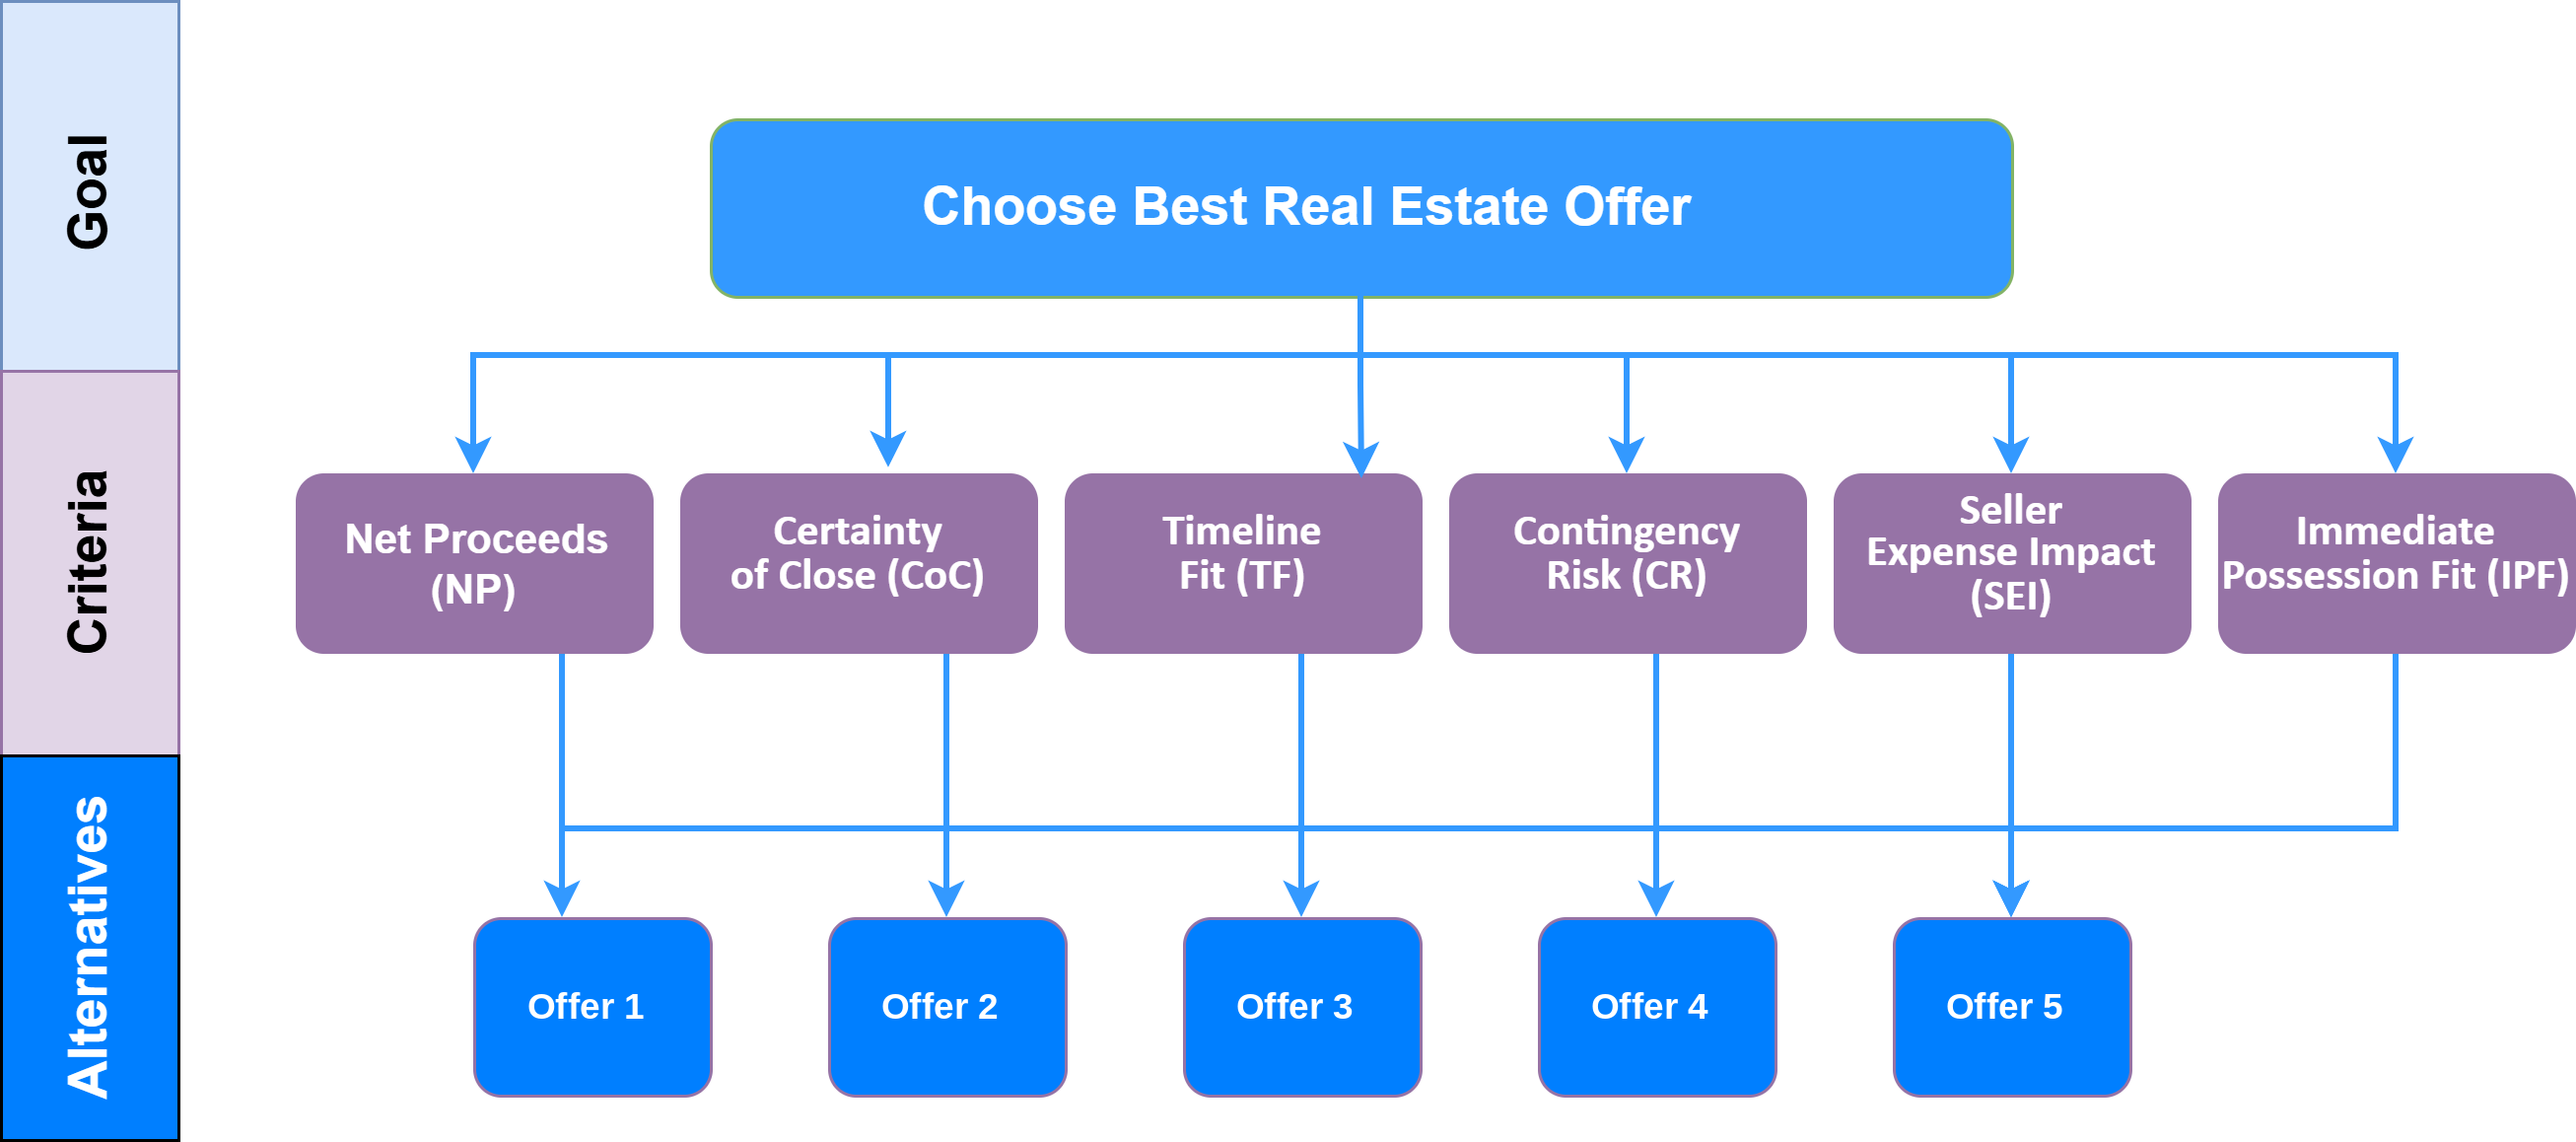

In [5]:
from IPython.display import Image, display

criteria_names = ["NP", "CoC", "TF", "CR", "SEI", "IPF"]

display(Image(filename=FIGDIR + "fig1_hierarchy.png", width=760))

#### 1.2 Pairwise comparison of criteria

Judgements on Saaty's 1-9 fundamental scale. A value above 1 means the row criterion is
preferred to the column criterion; reciprocals are entered explicitly.

In [6]:
criteria_matrix = np.array([
    [1,     3,     5,     5,     7,   9],   # NP compared to the others
    [1/3,   1,     3,     3,     5,   7],   # CoC
    [1/5,   1/3,   1,     1,     3,   5],   # TF
    [1/5,   1/3,   1,     1,     3,   5],   # CR
    [1/7,   1/5,   1/3,   1/3,   1,   3],   # SEI
    [1/9,   1/7,   1/5,   1/5,   1/3, 1]    # IPF
])

criteria_df = pd.DataFrame(criteria_matrix, index=criteria_names, columns=criteria_names)
criteria_df = criteria_df.map(lambda x: str(int(x)) if float(x).is_integer() else f"{x:.2f}")

print("Criteria Pairwise Comparison Matrix")
criteria_df

Criteria Pairwise Comparison Matrix


,NP,CoC,TF,CR,SEI,IPF
NP,1,3,5,5,7,9
CoC,0.33,1,3,3,5,7
TF,0.20,0.33,1,1,3,5
CR,0.20,0.33,1,1,3,5
SEI,0.14,0.20,0.33,0.33,1,3
IPF,0.11,0.14,0.20,0.20,0.33,1


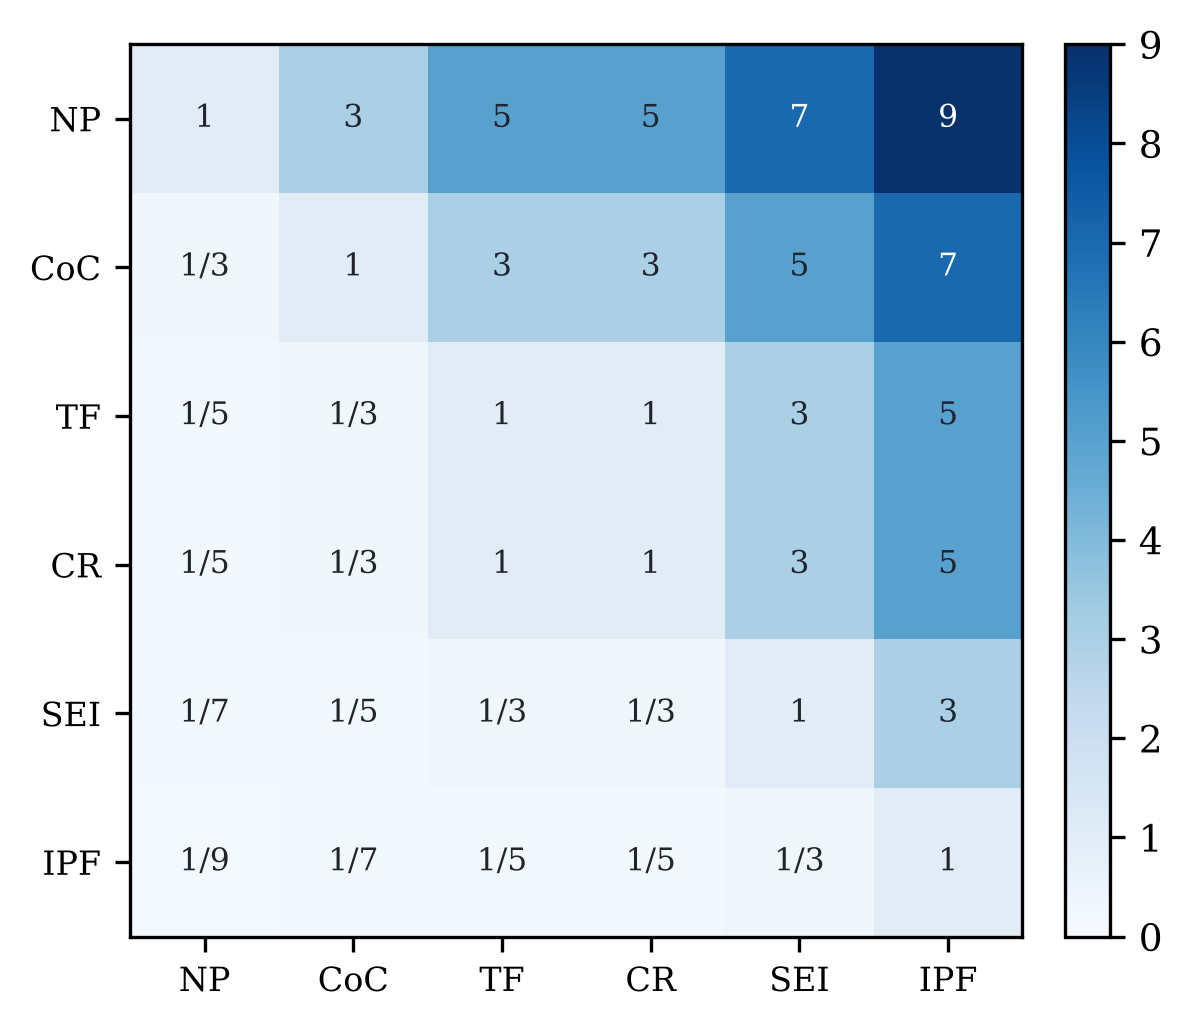

In [7]:
with plt.rc_context(FIGSTYLE):
    fig, ax = plt.subplots(figsize=(4.1, 3.5))
    im = ax.imshow(criteria_matrix, cmap="Blues", vmin=0, vmax=9)

    # annotate reciprocals as fractions so the scale reads the way it was entered
    for i in range(len(criteria_names)):
        for j in range(len(criteria_names)):
            v = criteria_matrix[i, j]
            text = f"{v:.0f}" if v >= 1 else f"1/{round(1/v):.0f}"
            ax.text(j, i, text, ha="center", va="center", fontsize=7.5,
                    color="white" if v > 5 else "#20242c")

    ax.set_xticks(range(len(criteria_names)))
    ax.set_xticklabels(criteria_names, fontsize=8)
    ax.set_yticks(range(len(criteria_names)))
    ax.set_yticklabels(criteria_names, fontsize=8)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(FIGDIR + "fig2_pairwise.png", bbox_inches="tight")
    plt.show()

#### 1.3 Criteria weights and consistency

Two derivations are shown. The row-average method normalises each column and averages the rows,
which is a quick approximation. The principal eigenvector is the standard AHP derivation and is
the one carried forward into all scoring, ablation and sensitivity work below.

In [8]:
col_sum = criteria_matrix.sum(axis=0)
norm_matrix = criteria_matrix / col_sum
criteria_weights_rowavg = norm_matrix.mean(axis=1)

pd.DataFrame({"Criteria": criteria_names, "Weight": criteria_weights_rowavg})

,Criteria,Weight
0,NP,0.452248
1,CoC,0.238154
2,TF,0.113149
3,CR,0.113149
4,SEI,0.054471
5,IPF,0.028830


In [9]:
eigvals, eigvecs = np.linalg.eig(criteria_matrix)

# principal eigenvalue and its eigenvector
idx = np.argmax(eigvals.real)
lambda_max = eigvals.real[idx]
principal_eigvec = eigvecs[:, idx].real

criteria_weights = principal_eigvec / principal_eigvec.sum()

# Consistency Index and Consistency Ratio against Saaty's Random Index
n_crit = criteria_matrix.shape[0]
CI = (lambda_max - n_crit) / (n_crit - 1.0)

RI_table = {1:0.00, 2:0.00, 3:0.58, 4:0.90, 5:1.12, 6:1.24, 7:1.32, 8:1.41, 9:1.45, 10:1.49}
RI = RI_table.get(n_crit, 1.49)
CR = CI / RI if RI != 0 else 0.0

print("Consistency Check:")
print(f"  Principal eigenvalue (lambda_max): {lambda_max:.6f}")
print(f"  CI = {CI:.6f}, RI({n_crit}) = {RI:.3f}, CR = {CR:.6f}")
print("  Consistency acceptable (CR <= 0.10)." if CR <= 0.10
      else "  WARNING: CR > 0.10 - judgments may be inconsistent.")

print("\nWeight derivation comparison:")
pd.DataFrame({"Row average": criteria_weights_rowavg,
              "Eigenvector": criteria_weights}, index=criteria_names).round(4)

Consistency Check:
  Principal eigenvalue (lambda_max): 6.257788
  CI = 0.051558, RI(6) = 1.240, CR = 0.041579
  Consistency acceptable (CR <= 0.10).

Weight derivation comparison:


,Row average,Eigenvector
NP,0.4522,0.4615
CoC,0.2382,0.2402
TF,0.1131,0.1095
CR,0.1131,0.1095
SEI,0.0545,0.0515
IPF,0.0288,0.0279


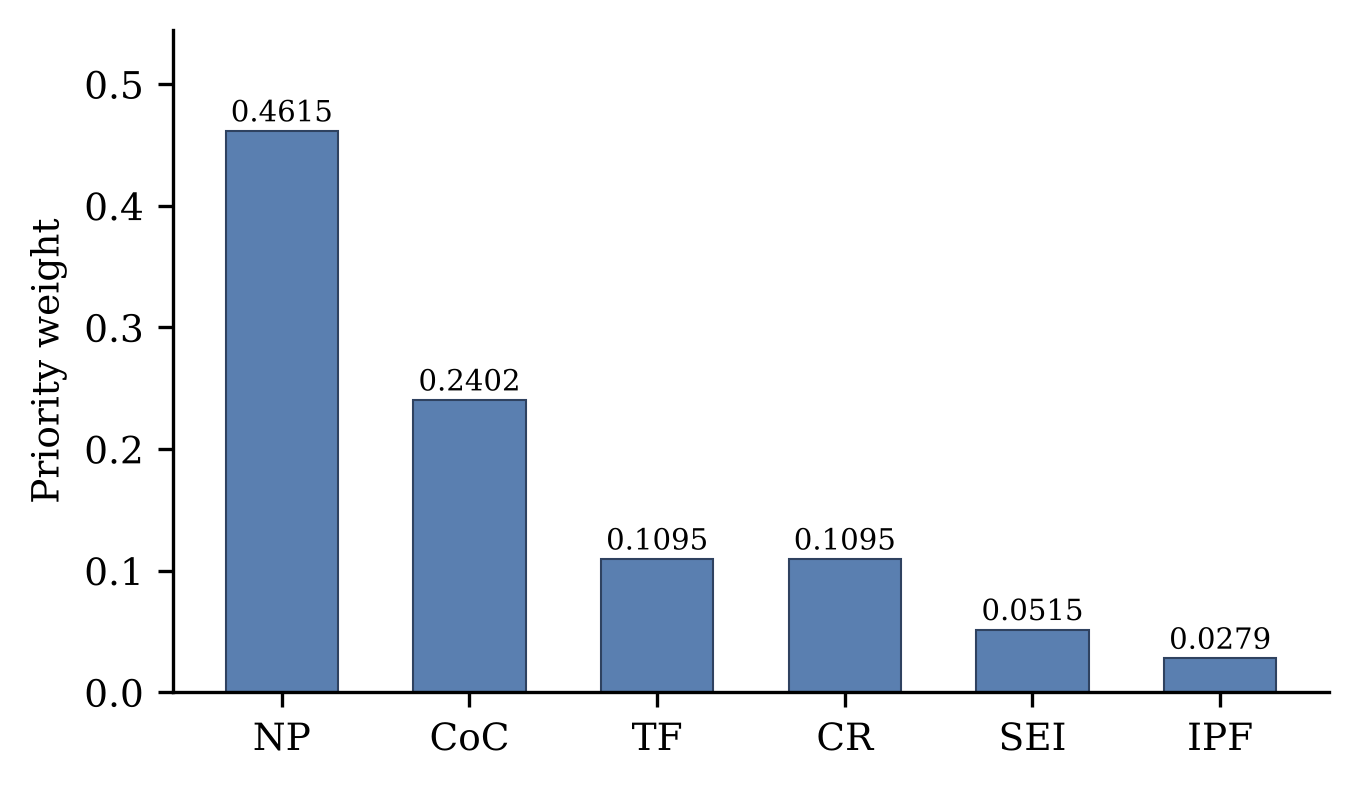

In [10]:
with plt.rc_context(FIGSTYLE):
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    bars = ax.bar(criteria_names, criteria_weights, color="#5a7fb0", width=0.6,
                  edgecolor="#2f4260", lw=0.5)
    for bar, value in zip(bars, criteria_weights):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.008, f"{value:.4f}",
                ha="center", fontsize=7)
    ax.set_ylabel("Priority weight")
    ax.set_ylim(0, max(criteria_weights) * 1.18)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.savefig(FIGDIR + "fig4_weights.png", bbox_inches="tight")
    plt.show()

#### 1.4 Converting offer data into criteria scores

Each criterion is computed from the recorded contract terms and placed on a 0-1 scale where a
higher value is always more preferable. Benefit criteria are scaled against the best value in
the set. Cost criteria (CR, SEI) are inverted with `min(x) / x`, which keeps them on a ratio
scale and maps the best performer to 1.0 without forcing the worst to zero.

In [11]:
# Seller's preferred closing date
preferred_closing = datetime.strptime("2025-10-25", "%Y-%m-%d")

# Net Proceeds (NP): higher is better
np_scores = []
for o in offers:
    np_val = o["offer_price"] - o["discount_amount"]
    np_val -= o["buyer_agent_commission"]["amount"] if o["buyer_agent_commission"]["paid_by_seller"] == "yes" else 0
    np_val -= o["buyer_closing_cost"]["amount"] if o["buyer_closing_cost"]["paid_by_seller"] == "yes" else 0
    np_val -= o["down_payment_assistance"]["amount"] if o["down_payment_assistance"]["paid_by_seller"] == "yes" else 0
    np_scores.append(np_val)
raw_np_scores = np.array(np_scores, dtype=float)
np_scores = raw_np_scores / raw_np_scores.max()  # normalize

# Certainty of Close (CoC): cash closes most reliably, alternative financing least
financing_map = {"Cash": 1.0, "None": 0.8, "Contract for deed": 0.6, "Other": 0.5}
coc_scores = []
for o in offers:
    if o["cash_offer"]["all_cash"] == "yes":
        coc_scores.append(1.0)
    else:
        coc_scores.append(financing_map.get(o["other_financing"], 0.5))
coc_scores = np.array(coc_scores)

# Timeline Fit (TF): linear decay in the deviation from the preferred closing date,
# reaching zero at 30 days either side
tf_scores = []
for o in offers:
    closing_date = datetime.strptime(o["proposed_closing_date"], "%Y-%m-%d")
    days_diff = abs((closing_date - preferred_closing).days)
    tf_scores.append(max(0, 1 - days_diff / 30))
tf_scores = np.array(tf_scores)

# Contingency Risk (CR): seller-paid repairs, replacements and other requests, plus the
# inspection period priced at $1,000 per day
raw_cr_scores = []
for o in offers:
    cr = o["repairs"]["amount"] + o["replacement_items"]["amount"] + o["other_requests"]["amount"]
    cr += o["inspection_request"]["days"] * 1000
    raw_cr_scores.append(cr)
raw_cr_scores = np.array(raw_cr_scores, dtype=float)
cr_scores = raw_cr_scores.min() / raw_cr_scores  # invert because cost criterion

# Seller Expense Impact (SEI): what the buyer asks the seller to carry
raw_sei_scores = []
for o in offers:
    sei = 0
    sei += o["buyer_agent_commission"]["amount"] if o["buyer_agent_commission"]["paid_by_seller"] == "yes" else 0
    sei += o["buyer_closing_cost"]["amount"] if o["buyer_closing_cost"]["paid_by_seller"] == "yes" else 0
    sei += o["down_payment_assistance"]["amount"] if o["down_payment_assistance"]["paid_by_seller"] == "yes" else 0
    raw_sei_scores.append(sei)
raw_sei_scores = np.array(raw_sei_scores, dtype=float)

# an offer asking nothing of the seller is the ideal case and takes the top score; the rest are
# measured against half the smallest positive expense in the set
if (raw_sei_scores == 0).any():
    sei_ref = raw_sei_scores[raw_sei_scores > 0].min() / 2
else:
    sei_ref = raw_sei_scores.min()
sei_scores = np.where(raw_sei_scores == 0, 1.0, sei_ref / raw_sei_scores)

# Immediate Possession Fit (IPF): yes = 1, no = 0
ipf_scores = np.array([1 if o["immediate_possession"] == "yes" else 0 for o in offers])

In [12]:
decision_matrix = np.vstack([np_scores, coc_scores, tf_scores,
                             cr_scores, sei_scores, ipf_scores]).T

decision_df = pd.DataFrame(decision_matrix, columns=criteria_names, index=offer_index)

print("Decision Matrix")
decision_df.round(4)

Decision Matrix


,NP,CoC,TF,CR,SEI,IPF
Offer 1,0.9449,0.8,0.8333,0.7222,0.3000,1.0
Offer 2,0.9738,1.0,1.0000,0.5652,0.3750,0.0
Offer 3,0.9869,0.6,0.8333,1.0000,0.1667,1.0
Offer 4,0.9816,1.0,0.9000,0.6190,1.0000,0.0
Offer 5,1.0000,0.8,0.9667,0.9286,0.5000,1.0


Descriptive Statistics:
          NP    CoC     TF     CR    SEI    IPF
count  5.000  5.000  5.000  5.000  5.000  5.000
mean   0.977  0.840  0.907  0.767  0.468  0.600
std    0.021  0.167  0.076  0.190  0.321  0.548
min    0.945  0.600  0.833  0.565  0.167  0.000
25%    0.974  0.800  0.833  0.619  0.300  0.000
50%    0.982  0.800  0.900  0.722  0.375  1.000
75%    0.987  1.000  0.967  0.929  0.500  1.000
max    1.000  1.000  1.000  1.000  1.000  1.000


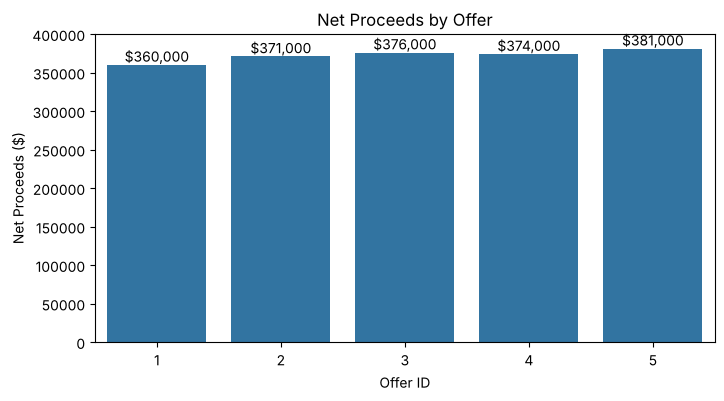

In [13]:
print("Descriptive Statistics:")
print(decision_df.describe().round(3))

# raw net proceeds behind the normalised NP column
np_df = pd.DataFrame({"OfferID": [o["id"] for o in offers], "NP": raw_np_scores})

plt.figure(figsize=(8, 4))
barplot = sns.barplot(x="OfferID", y="NP", data=np_df)
for p in barplot.patches:
    barplot.annotate(f"${int(p.get_height()):,}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="bottom", fontsize=10)
plt.title("Net Proceeds by Offer")
plt.xlabel("Offer ID")
plt.ylabel("Net Proceeds ($)")
plt.show()

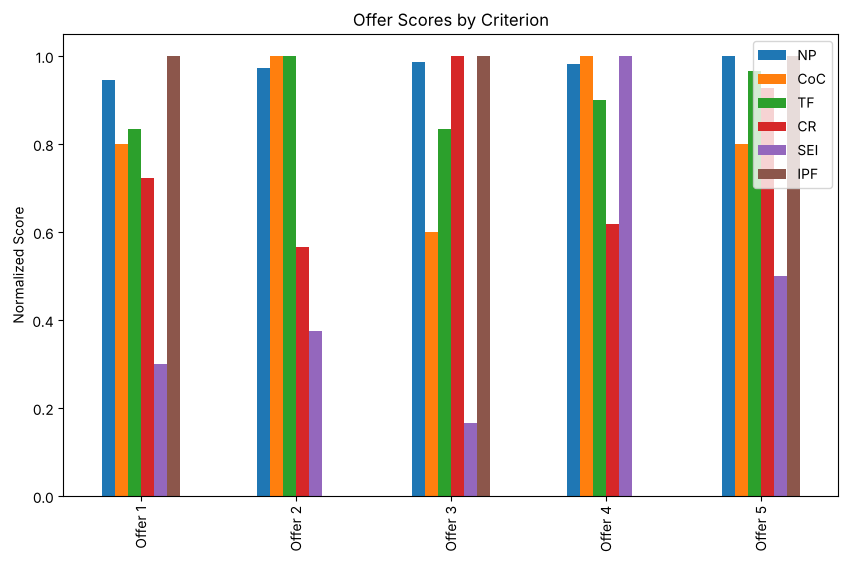

In [14]:
decision_df.plot(kind="bar", figsize=(10, 6))
plt.title("Offer Scores by Criterion")
plt.ylabel("Normalized Score")
plt.show()

No offer dominates the others. The radar plot below shows where each one gives ground.

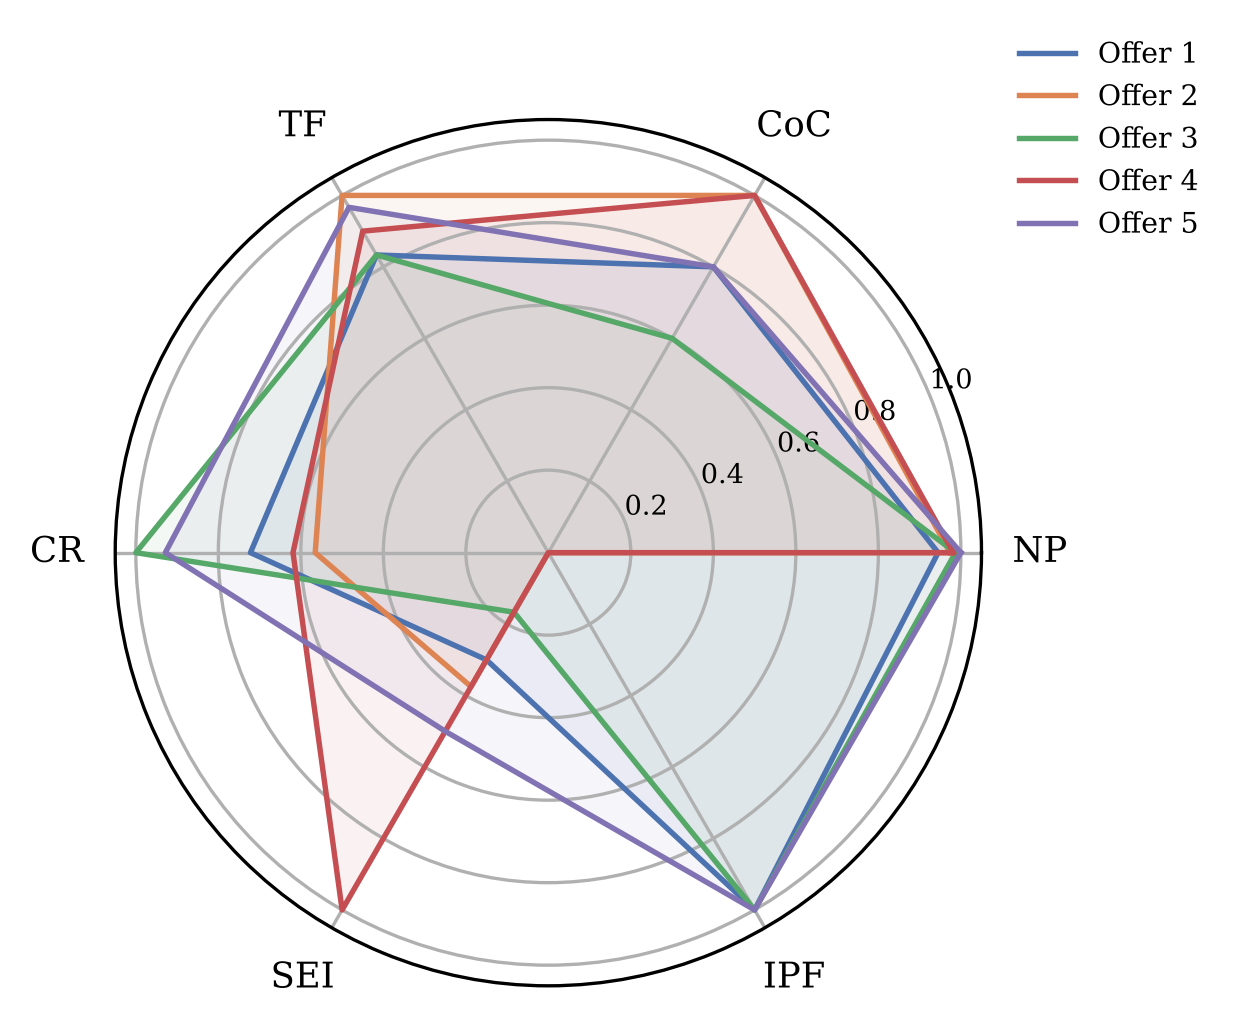

In [15]:
with plt.rc_context(FIGSTYLE):
    angles = np.linspace(0, 2 * np.pi, len(criteria_names), endpoint=False).tolist()
    angles += angles[:1]  # close the loop

    fig, ax = plt.subplots(figsize=(4.3, 4.3), subplot_kw=dict(polar=True))
    for i, row in enumerate(decision_matrix):
        values = list(row) + [row[0]]
        ax.plot(angles, values, lw=1.3, color=PALETTE[i % len(PALETTE)], label=offer_index[i])
        ax.fill(angles, values, alpha=0.07, color=PALETTE[i % len(PALETTE)])

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(criteria_names, fontsize=8.5)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=6.5)
    ax.legend(loc="upper right", bbox_to_anchor=(1.28, 1.12), fontsize=6.8, frameon=False)
    plt.tight_layout()
    plt.savefig(FIGDIR + "fig3_criteria_profile.png", bbox_inches="tight")
    plt.show()

#### 1.5 AHP ranking

In [16]:
ahp_scores = decision_matrix.dot(criteria_weights)

results_df = decision_df.copy()
results_df["Final Score"] = ahp_scores
results_df["Rank"] = results_df["Final Score"].rank(ascending=False, method="min").astype(int)

print("Final Results:\n")
results_df.sort_values("Final Score", ascending=False).round(4)

Final Results:



,NP,CoC,TF,CR,SEI,IPF,Final Score,Rank
Offer 5,1.0000,0.8,0.9667,0.9286,0.5000,1.0,0.9148,1
Offer 4,0.9816,1.0,0.9000,0.6190,1.0000,0.0,0.9110,2
Offer 2,0.9738,1.0,1.0000,0.5652,0.3750,0.0,0.8803,3
Offer 1,0.9449,0.8,0.8333,0.7222,0.3000,1.0,0.8418,4
Offer 3,0.9869,0.6,0.8333,1.0000,0.1667,1.0,0.8367,5


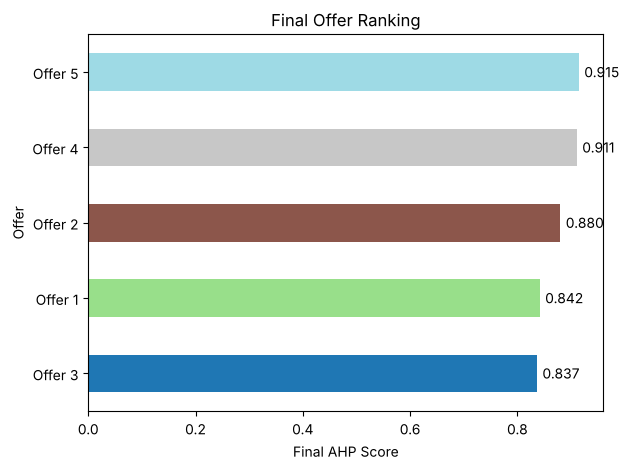

In [17]:
sorted_df = results_df.sort_values("Final Score", ascending=True)
colors = plt.get_cmap("tab20", len(sorted_df))

ax = sorted_df.reset_index().plot(
    kind="barh", x="index", y="Final Score", legend=False,
    color=[colors(i) for i in range(len(sorted_df))]
)
for i, v in enumerate(sorted_df["Final Score"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")

plt.xlabel("Final AHP Score")
plt.ylabel("Offer")
plt.title("Final Offer Ranking")
plt.tight_layout()
plt.show()

Plotting the final score against the headline price makes the central point visible: the two
highest-priced offers do not score highest once financing reliability, contingency exposure and
seller cost obligations are taken into account.

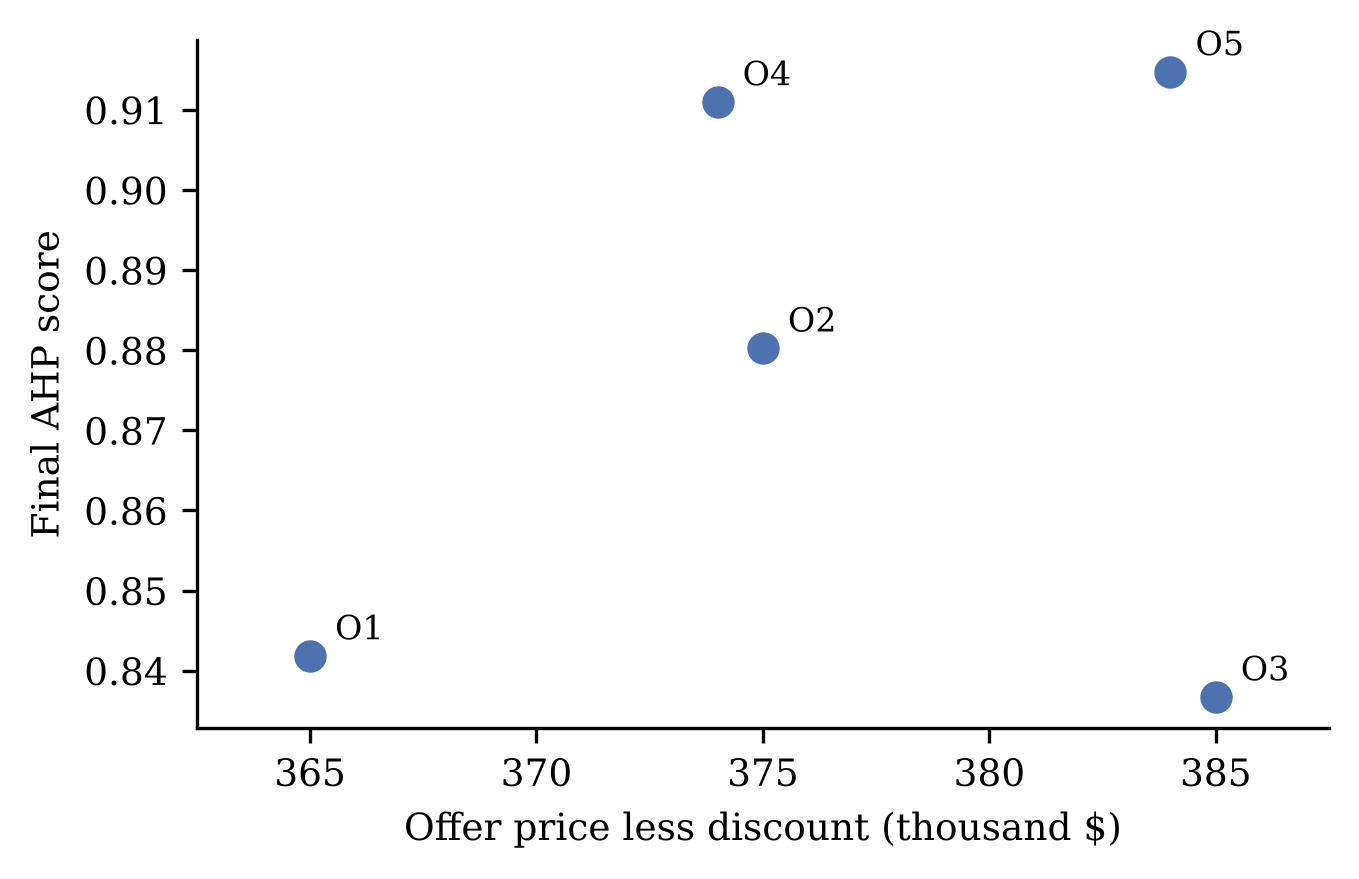

In [18]:
with plt.rc_context(FIGSTYLE):
    headline_price = np.array([o["offer_price"] - o["discount_amount"] for o in offers], dtype=float)

    fig, ax = plt.subplots(figsize=(4.6, 3.0))
    ax.scatter(headline_price, ahp_scores, s=46, color="#4c72b0", zorder=3)
    for i, label in enumerate(offer_labels):
        ax.annotate(label, (headline_price[i], ahp_scores[i]),
                    textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_xlabel("Offer price less discount (thousand $)")
    ax.set_ylabel("Final AHP score")
    # show prices in thousands and space the ticks so the labels do not overlap
    ax.xaxis.set_major_locator(plt.MultipleLocator(5000))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}"))
    ax.set_xlim(headline_price.min() - 2500, headline_price.max() + 2500)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.savefig(FIGDIR + "figS1_price_vs_score.png", bbox_inches="tight")
    plt.show()

### 2. TOPSIS

TOPSIS is run on the same decision matrix with the same AHP-derived weights, so any difference
in the ranking comes from the aggregation rule rather than from the priorities.

In [19]:
# Every criterion was put on a "higher is better" scale during scoring: CR and SEI were inverted
# there, and TF already rises as the proposed closing date approaches the preferred one. All six
# are therefore beneficial when the ideal best and ideal worst solutions are built.
criteria_types = {c: "+" for c in criteria_names}

# vector normalisation, then apply the AHP weights
norm_matrix = decision_df / np.sqrt((decision_df ** 2).sum())
weighted_matrix = norm_matrix * criteria_weights

ideal_best, ideal_worst = [], []
for crit in criteria_names:
    if criteria_types[crit] == "+":
        ideal_best.append(weighted_matrix[crit].max())
        ideal_worst.append(weighted_matrix[crit].min())
    else:
        ideal_best.append(weighted_matrix[crit].min())
        ideal_worst.append(weighted_matrix[crit].max())

ideal_best = np.array(ideal_best)
ideal_worst = np.array(ideal_worst)

# Euclidean distance to each ideal point
dist_best = np.sqrt(((weighted_matrix - ideal_best) ** 2).sum(axis=1))
dist_worst = np.sqrt(((weighted_matrix - ideal_worst) ** 2).sum(axis=1))

topsis_scores = dist_worst / (dist_best + dist_worst)

topsis_rankings = pd.DataFrame({
    "Offer": decision_df.index,
    "TOPSIS Score": topsis_scores,
    "Rank": topsis_scores.rank(ascending=False).astype(int)
}).sort_values("Rank")

print("TOPSIS Rankings:")
topsis_rankings

TOPSIS Rankings:


,Offer,TOPSIS Score,Rank
Offer 4,Offer 4,0.677965,1
Offer 5,Offer 5,0.560846,2
Offer 2,Offer 2,0.558280,3
Offer 1,Offer 1,0.416017,4
Offer 3,Offer 3,0.345533,5


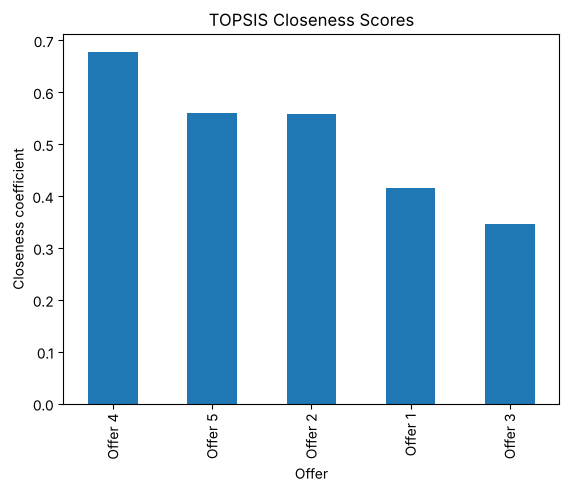

In [20]:
topsis_rankings.plot(kind="bar", x="Offer", y="TOPSIS Score", legend=False)
plt.title("TOPSIS Closeness Scores")
plt.ylabel("Closeness coefficient")
plt.show()

### 3. Comparing AHP and TOPSIS rankings

In [21]:
ahp_ranks = results_df["Rank"]
topsis_ranks = topsis_rankings.set_index("Offer")["Rank"].reindex(ahp_ranks.index)

comparison_df = pd.DataFrame({"AHP Rank": ahp_ranks, "TOPSIS Rank": topsis_ranks})

corr, p_value = spearmanr(ahp_ranks, topsis_ranks)
tau, tau_p = kendalltau(ahp_ranks, topsis_ranks)
print(f"Spearman Rank Correlation: {corr:.3f}, p-value: {p_value:.3f}")
print(f"Kendall's Tau: {tau:.3f}, p-value: {tau_p:.3f}\n")

comparison_df

Spearman Rank Correlation: 0.900, p-value: 0.037
Kendall's Tau: 0.800, p-value: 0.083



,AHP Rank,TOPSIS Rank
Offer 1,4,4
Offer 2,3,3
Offer 3,5,5
Offer 4,2,1
Offer 5,1,2


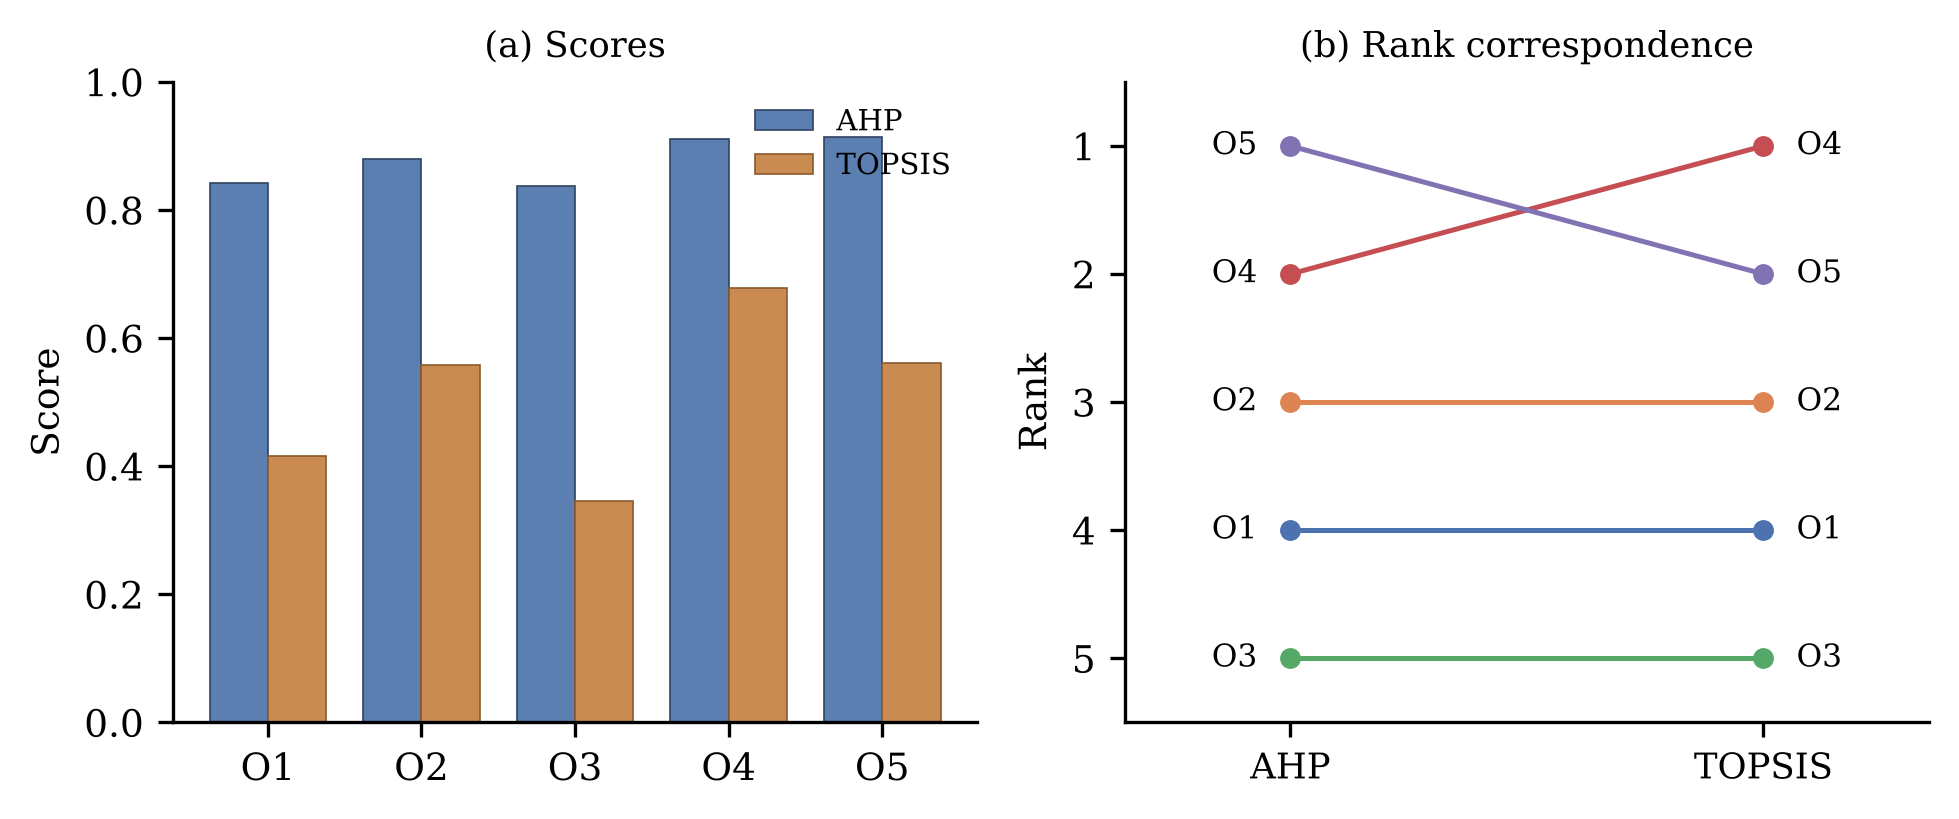

In [22]:
with plt.rc_context(FIGSTYLE):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.6, 2.8))
    x = np.arange(len(offers))
    width = 0.38

    ax1.bar(x - width / 2, ahp_scores, width, label="AHP",
            color="#5a7fb0", edgecolor="#2f4260", lw=0.4)
    ax1.bar(x + width / 2, topsis_scores, width, label="TOPSIS",
            color="#c98b52", edgecolor="#8a5a2c", lw=0.4)
    ax1.set_xticks(x)
    ax1.set_xticklabels(offer_labels)
    ax1.set_ylabel("Score")
    ax1.set_ylim(0, 1.0)
    ax1.legend(fontsize=7, frameon=False)
    ax1.set_title("(a) Scores", fontsize=8.5)

    # slope chart: a flat line means the two methods agree on that offer
    ra, rt = ahp_ranks.values, topsis_ranks.values
    for i in range(len(offers)):
        ax2.plot([0, 1], [ra[i], rt[i]], "-o", ms=4, color=PALETTE[i % len(PALETTE)], lw=1.2)
        ax2.text(-0.07, ra[i], offer_labels[i], ha="right", va="center", fontsize=7.5)
        ax2.text(1.07, rt[i], offer_labels[i], ha="left", va="center", fontsize=7.5)
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["AHP", "TOPSIS"], fontsize=8.5)
    ax2.set_ylim(len(offers) + 0.5, 0.5)
    ax2.set_yticks(range(1, len(offers) + 1))
    ax2.set_ylabel("Rank")
    ax2.set_xlim(-0.35, 1.35)
    ax2.set_title("(b) Rank correspondence", fontsize=8.5)

    for ax in (ax1, ax2):
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.savefig(FIGDIR + "fig5_ahp_topsis.png", bbox_inches="tight")
    plt.show()

### 4. Ablation study

Removing criteria shows whether SEI and IPF carry information or only add noise. Priorities are
recomputed from the corresponding submatrix in each configuration rather than reused.

In [23]:
def run_ahp(criteria_subset):
    indices = [criteria_names.index(c) for c in criteria_subset]

    cm = criteria_matrix[np.ix_(indices, indices)]   # subset pairwise comparison
    dm = decision_matrix[:, indices]                 # subset decision matrix

    eigvals, eigvecs = np.linalg.eig(cm)
    weights = eigvecs[:, np.argmax(eigvals.real)].real
    weights /= weights.sum()

    scores = dm.dot(weights)
    return {
        "subset": criteria_subset,
        "weights": weights,
        "scores": scores,
        "rankings": pd.Series(scores, index=offer_index).rank(ascending=False),
    }


subsets = {
    "Full 6":      ["NP", "CoC", "TF", "CR", "SEI", "IPF"],
    "4 Base":      ["NP", "CoC", "TF", "CR"],
    "5 minus SEI": ["NP", "CoC", "TF", "CR", "IPF"],
    "5 minus IPF": ["NP", "CoC", "TF", "CR", "SEI"],
}

results = {name: run_ahp(subset) for name, subset in subsets.items()}
modes = list(results)

rank_table = pd.DataFrame({k: r["rankings"] for k, r in results.items()}).astype(int)
rank_table

,Full 6,4 Base,5 minus SEI,5 minus IPF
Offer 1,4,5,5,4
Offer 2,3,1,2,3
Offer 3,5,4,4,5
Offer 4,2,2,3,1
Offer 5,1,3,1,2


In [24]:
score_table = pd.DataFrame({k: r["scores"] for k, r in results.items()}, index=offer_index)
score_table.round(4)

,Full 6,4 Base,5 minus SEI,5 minus IPF
Offer 1,0.8418,0.8768,0.8747,0.8456
Offer 2,0.8803,0.9438,0.9078,0.9136
Offer 3,0.8367,0.8770,0.8761,0.8400
Offer 4,0.9110,0.9438,0.9067,0.9415
Offer 5,0.9148,0.9401,0.9391,0.9173


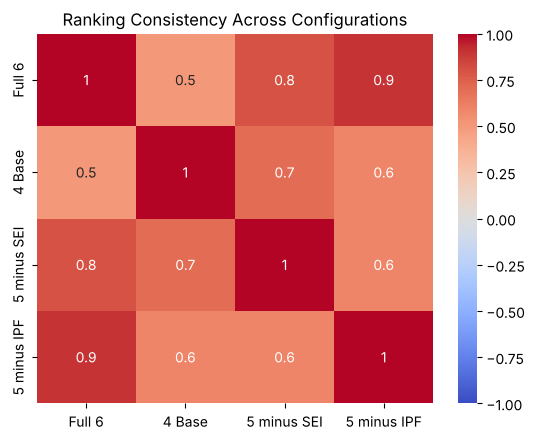

,Full 6,4 Base,5 minus SEI,5 minus IPF
Full 6,1.0,0.5,0.8,0.9
4 Base,0.5,1.0,0.7,0.6
5 minus SEI,0.8,0.7,1.0,0.6
5 minus IPF,0.9,0.6,0.6,1.0


In [25]:
spearman_matrix = pd.DataFrame(index=modes, columns=modes, dtype=float)
for a in modes:
    for b in modes:
        spearman_matrix.loc[a, b] = spearmanr(results[a]["rankings"], results[b]["rankings"]).correlation

sns.heatmap(spearman_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ranking Consistency Across Configurations")
plt.show()

spearman_matrix.round(3)

### 5. Sensitivity analysis

Each off-diagonal judgement is perturbed by plus and minus 10 per cent in turn, with the
reciprocal adjusted to match, and the ranking recomputed. The question is how often the order
of the offers changes at all.

In [26]:
def run_sensitivity(matrix, dmatrix, names, pct=0.10):
    eigvals, eigvecs = np.linalg.eig(matrix)
    weights_orig = eigvecs[:, np.argmax(eigvals.real)].real
    weights_orig /= weights_orig.sum()
    rank_orig = pd.Series(dmatrix.dot(weights_orig), index=offer_index).rank(ascending=False)

    rows = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            for change in (1 + pct, 1 - pct):
                mat_sens = matrix.copy()
                mat_sens[i, j] = matrix[i, j] * change
                mat_sens[j, i] = 1 / mat_sens[i, j]

                eig_s, eigvec_s = np.linalg.eig(mat_sens)
                weights_s = eigvec_s[:, np.argmax(eig_s.real)].real
                weights_s /= weights_s.sum()

                rank_s = pd.Series(dmatrix.dot(weights_s), index=offer_index).rank(ascending=False)
                rows.append({
                    "Pair": f"{names[i]} vs {names[j]}",
                    "Perturbation": f"{(change - 1) * 100:+.1f}%",
                    "MaxRankShift": int((rank_s - rank_orig).abs().max()),
                    "Spearman": rank_s.corr(rank_orig, method="spearman"),
                })
    return pd.DataFrame(rows)


sensitivity = {}
for name, subset in subsets.items():
    indices = [criteria_names.index(c) for c in subset]
    sensitivity[name] = run_sensitivity(
        criteria_matrix[np.ix_(indices, indices)], decision_matrix[:, indices], subset
    )

In [27]:
summary = pd.DataFrame([{
    "Configuration": name,
    "Perturbations": len(df),
    "Producing a shift": int((df["MaxRankShift"] > 0).sum()),
    "Max rank shift": int(df["MaxRankShift"].max()),
    "Mean Spearman": round(df["Spearman"].mean(), 3),
} for name, df in sensitivity.items()])

summary

,Configuration,Perturbations,Producing a shift,Max rank shift,Mean Spearman
0,Full 6,30,0,0,1.000
1,4 Base,12,10,1,0.908
2,5 minus SEI,20,1,1,0.995
3,5 minus IPF,20,0,0,1.000


In [28]:
# the individual judgements responsible, where any configuration moved
unstable = sensitivity["4 Base"].sort_values("MaxRankShift", ascending=False)
unstable[unstable["MaxRankShift"] > 0]

,Pair,Perturbation,MaxRankShift,Spearman
0,NP vs CoC,+10.0%,1,0.9
1,NP vs CoC,-10.0%,1,0.9
2,NP vs TF,+10.0%,1,0.9
3,NP vs TF,-10.0%,1,0.9
5,NP vs CR,-10.0%,1,0.9
6,CoC vs TF,+10.0%,1,0.8
9,CoC vs CR,-10.0%,1,0.9
8,CoC vs CR,+10.0%,1,0.9
10,TF vs CR,+10.0%,1,0.9
11,TF vs CR,-10.0%,1,0.9


### 6. Normalisation scheme comparison

The cost criteria have to be turned into "higher is better" scores before they can be
aggregated, and the transformation used for that is a modelling decision in its own right.
Two are compared:

- **Ratio**, `min(x) / x`, used throughout above. Preserves the ratio scale AHP assumes and
  maps the best performer to 1.0 without forcing the worst to 0.
- **Linear range**, `(max(x) - x) / (max(x) - min(x))`. Widely used, but it compresses the set
  and assigns exactly 0 to the worst performer on each cost criterion.

Running both separates conclusions that hold either way from conclusions that depend on the
transformation.

In [29]:
def linear_invert(x):
    x = np.array(x, dtype=float)
    return (x.max() - x) / (x.max() - x.min())


decision_matrix_linear = decision_matrix.copy()
decision_matrix_linear[:, criteria_names.index("CR")] = linear_invert(raw_cr_scores)
decision_matrix_linear[:, criteria_names.index("SEI")] = linear_invert(raw_sei_scores)

pd.DataFrame(decision_matrix_linear, columns=criteria_names, index=offer_index).round(4)

,NP,CoC,TF,CR,SEI,IPF
Offer 1,0.9449,0.8,0.8333,0.5,0.4444,1.0
Offer 2,0.9738,1.0,1.0000,0.0,0.5556,0.0
Offer 3,0.9869,0.6,0.8333,1.0,0.0000,1.0
Offer 4,0.9816,1.0,0.9000,0.2,1.0000,0.0
Offer 5,1.0000,0.8,0.9667,0.9,0.6667,1.0


In [30]:
def topsis_scores_for(dmatrix, weights):
    df = pd.DataFrame(dmatrix, columns=criteria_names)
    wm = (df / np.sqrt((df ** 2).sum())) * weights
    d_best = np.sqrt(((wm - wm.max().values) ** 2).sum(axis=1))
    d_worst = np.sqrt(((wm - wm.min().values) ** 2).sum(axis=1))
    return (d_worst / (d_best + d_worst)).values


ahp_linear = decision_matrix_linear.dot(criteria_weights)
topsis_linear = topsis_scores_for(decision_matrix_linear, criteria_weights)

rank = lambda s: pd.Series(s).rank(ascending=False).astype(int).values

norm_compare = pd.DataFrame({
    "AHP (ratio)": ahp_scores,
    "rank": rank(ahp_scores),
    "TOPSIS (ratio)": topsis_scores.values,
    "rank ": rank(topsis_scores.values),
    "AHP (linear)": ahp_linear,
    "rank  ": rank(ahp_linear),
    "TOPSIS (linear)": topsis_linear,
    "rank   ": rank(topsis_linear),
}, index=offer_index)

print("Spearman AHP vs TOPSIS, ratio scheme :",
      round(spearmanr(ahp_scores, topsis_scores).correlation, 3))
print("Spearman AHP vs TOPSIS, linear scheme:",
      round(spearmanr(ahp_linear, topsis_linear).correlation, 3), "\n")

norm_compare.round(4)

Spearman AHP vs TOPSIS, ratio scheme : 0.9
Spearman AHP vs TOPSIS, linear scheme: 0.8 



,AHP (ratio),rank,TOPSIS (ratio),rank,AHP (linear),rank,TOPSIS (linear),rank
Offer 1,0.8418,4,0.4160,4,0.8249,5,0.4949,4
Offer 2,0.8803,3,0.5583,3,0.8277,4,0.4119,5
Offer 3,0.8367,5,0.3455,5,0.8281,3,0.5520,2
Offer 4,0.9110,2,0.6780,1,0.8651,2,0.5074,3
Offer 5,0.9148,1,0.5608,2,0.9202,1,0.7320,1


In [31]:
for label, dmatrix in (("Ratio ", decision_matrix), ("Linear", decision_matrix_linear)):
    df = run_sensitivity(criteria_matrix, dmatrix, criteria_names)
    print(f"{label}: {int((df['MaxRankShift'] > 0).sum())} of {len(df)} perturbations shift a rank, "
          f"max shift {int(df['MaxRankShift'].max())}")

Ratio : 0 of 30 perturbations shift a rank, max shift 0
Linear: 14 of 30 perturbations shift a rank, max shift 1


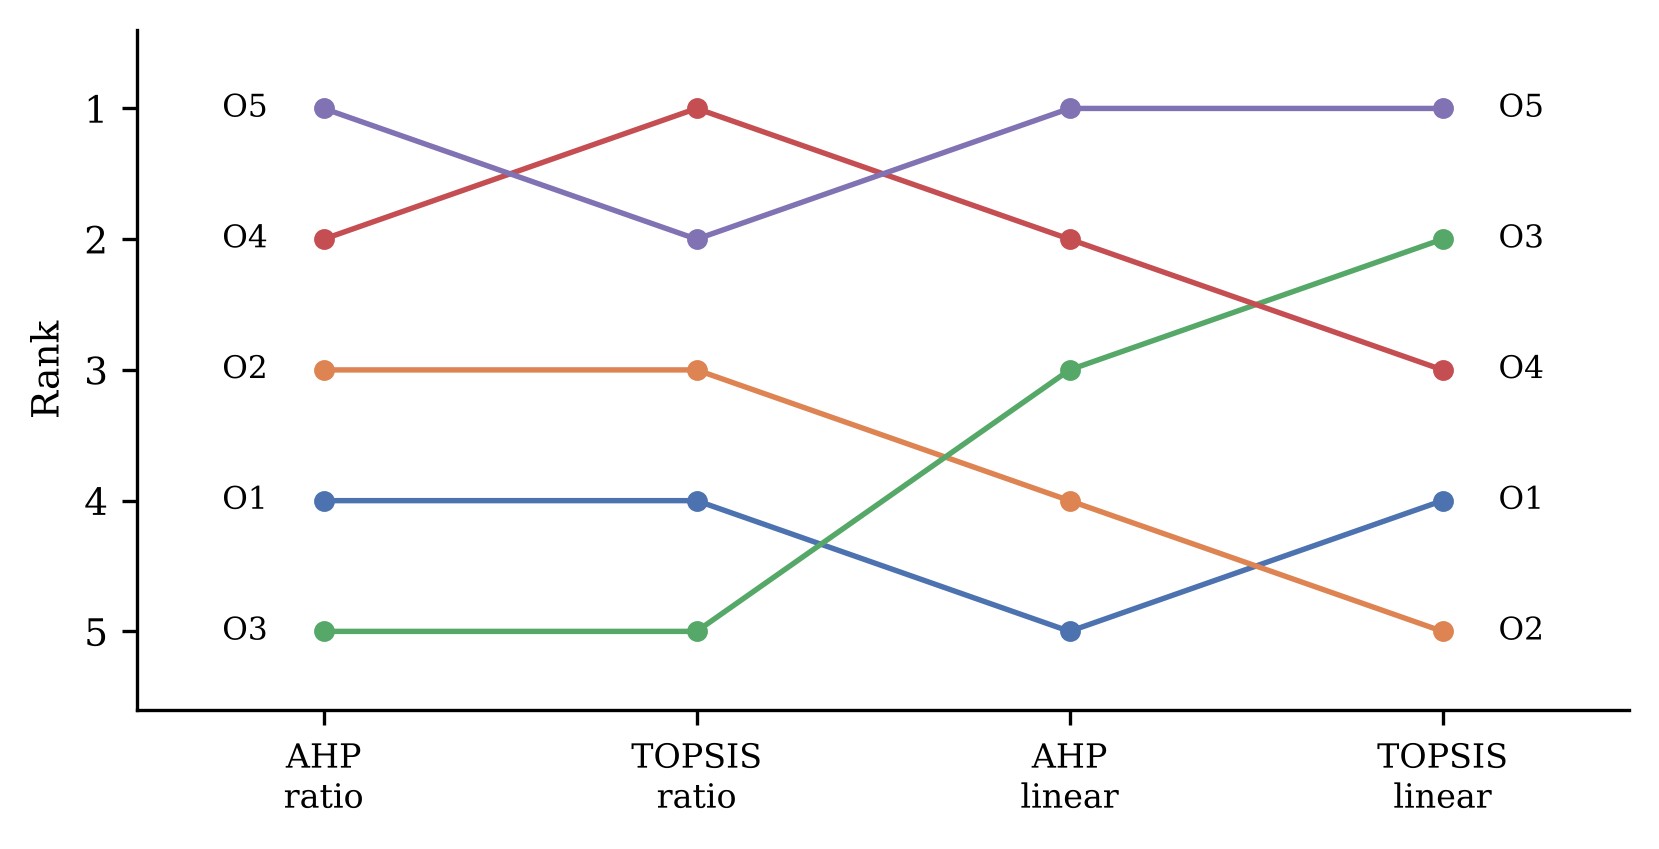

In [32]:
with plt.rc_context(FIGSTYLE):
    fig, ax = plt.subplots(figsize=(5.6, 2.9))
    cols = [
        ("AHP\nratio",     rank(ahp_scores)),
        ("TOPSIS\nratio",  rank(topsis_scores.values)),
        ("AHP\nlinear",    rank(ahp_linear)),
        ("TOPSIS\nlinear", rank(topsis_linear)),
    ]
    xs = np.arange(len(cols))
    R = np.array([r for _, r in cols])          # shape (4, n_offers)

    # one line per offer; a flat line means the offer keeps its rank
    for i in range(len(offers)):
        ax.plot(xs, R[:, i], "-o", ms=4, lw=1.3, color=PALETTE[i % len(PALETTE)])
        ax.text(xs[0] - 0.15, R[0, i], offer_labels[i], ha="right", va="center", fontsize=7.5)
        ax.text(xs[-1] + 0.15, R[-1, i], offer_labels[i], ha="left", va="center", fontsize=7.5)

    ax.set_xticks(xs)
    ax.set_xticklabels([c for c, _ in cols], fontsize=8)
    ax.set_xlim(-0.5, len(cols) - 0.5)
    ax.set_ylim(len(offers) + 0.6, 0.4)
    ax.set_yticks(range(1, len(offers) + 1))
    ax.set_ylabel("Rank")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.savefig(FIGDIR + "fig6_rank_comparison.png", bbox_inches="tight")
    plt.show()